# Local model audit and Responsible AI dashboard concepts

Reuse the fixed energy SVR and held-out December data from the time-series
lesson. This notebook actually runs error analysis, cohort comparison,
representation checks, global feature importance, and an exact local
explanation of the selected linear SVR.

**Scope:** this is a local exercise using pandas and scikit-learn. It does
not claim to execute the external Azure Responsible AI dashboard or its
sample notebook, which remains an approved exclusion. The companion
[paper](answers.md) distinguishes the published dashboard components from
these independently executed results.

In [1]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
from sklearn.tree import DecisionTreeRegressor,plot_tree

source=Path('../../7-TimeSeries/3-SVR')
# This is the trusted model exported by our preceding, executed notebook.
model=joblib.load(source/'energy-svr.joblib')
train=pd.read_csv(source/'model-training.csv',parse_dates=['timestamp']).set_index('timestamp')
test=pd.read_csv(source/'model-test.csv',parse_dates=['timestamp']).set_index('timestamp')
features=train.columns.drop('target')
X=test[features]
prediction=model.predict(X)
np.testing.assert_allclose(prediction,test.prediction)
assert train.index.max()<test.index.min() and len(test)==744
audit=test.copy()
audit['absolute_error']=(audit.prediction-audit.target).abs()
audit['underprediction']=audit.prediction<audit.target
audit['hour']=audit.index.hour
audit['weekend']=audit.index.dayofweek>=5
audit['peak_window']=audit.hour.between(16,20)
display(pd.DataFrame([
    {'method':name,'MAE':mean_absolute_error(audit.target,audit[name]),
     'MAPE_percent':100*mean_absolute_percentage_error(audit.target,audit[name])}
    for name in ['prediction','persistence','daily_naive']
]))

,method,MAE,MAPE_percent
0,prediction,36.686760,1.072979
1,persistence,131.279570,3.903000
2,daily_naive,162.205645,4.791932


In [2]:
rows=[]
for field in ['weekend','peak_window']:
    for value,group in audit.groupby(field):
        rows.append({'cohort':field,'value':bool(value),'n':len(group),
                     'MAE':group.absolute_error.mean(),
                     'MAPE_percent':100*mean_absolute_percentage_error(group.target,group.prediction),
                     'underprediction_rate':group.underprediction.mean()})
cohorts=pd.DataFrame(rows)
display(cohorts)
cohorts.to_csv('cohort-metrics.csv',index=False)
print('Training/test hour representation:')
hour_counts=pd.DataFrame({'training':train.groupby(train.index.hour).size(),
                          'test':test.groupby(test.index.hour).size()})
display(hour_counts)
hour_counts.to_csv('hour-representation.csv',index_label='hour')
assert hour_counts.test.sum()==744

,cohort,value,n,MAE,MAPE_percent,underprediction_rate
0,weekend,False,552,36.810582,1.066873,0.581522
1,weekend,True,192,36.330773,1.090533,0.447917
2,peak_window,False,589,34.558502,1.056848,0.536503
3,peak_window,True,155,44.774140,1.134276,0.587097


Training/test hour representation:


,training,test
timestamp,,
0,91,31
1,91,31
2,91,31
3,91,31
4,91,31
5,91,31
6,91,31
7,91,31
8,91,31


## Error analysis

Fit a shallow tree to the observed December absolute errors to identify
candidate cohorts. This describes this test period; it is not an unbiased
validation of a newly discovered error rule. Any model changed in response
would need a later untouched evaluation period.

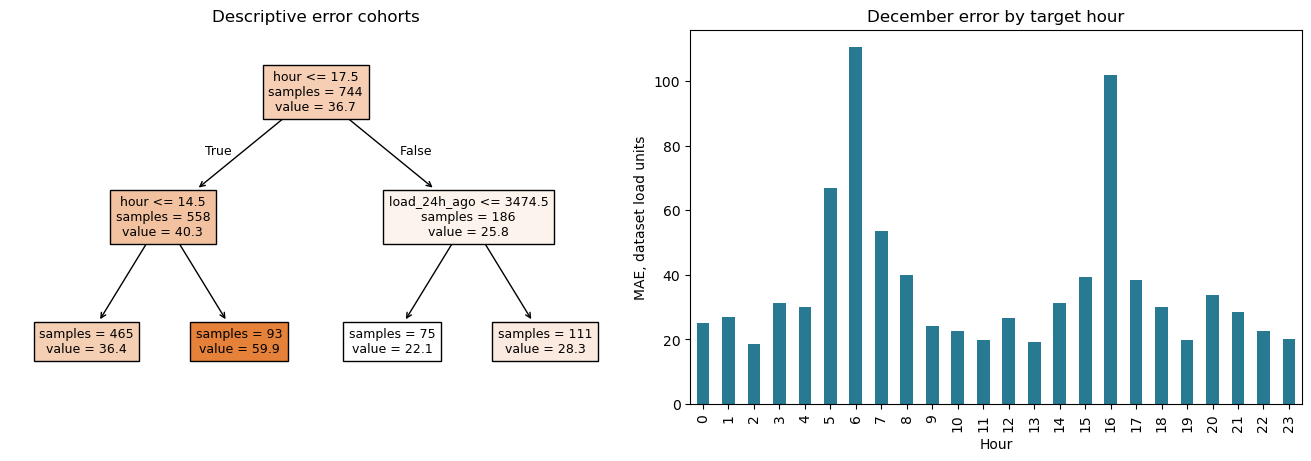

In [3]:
error_features=pd.DataFrame({'hour':audit.hour,'last_load':audit.lag_1,
                              'load_24h_ago':audit.lag_24},index=audit.index)
tree=DecisionTreeRegressor(max_depth=2,min_samples_leaf=75,random_state=42)
tree.fit(error_features,audit.absolute_error)
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
plot_tree(tree,feature_names=error_features.columns,filled=True,rounded=False,
          impurity=False,precision=1,ax=axes[0],fontsize=9)
axes[0].set_title('Descriptive error cohorts')
audit.groupby('hour').absolute_error.mean().plot.bar(ax=axes[1],color='#287a92')
axes[1].set(title='December error by target hour',xlabel='Hour',ylabel='MAE, dataset load units')
fig.savefig('error-analysis.png',dpi=150)
plt.show()

,feature,MAE_increase,repeat_std
0,lag_1,932.363359,19.011047
1,lag_2,590.321231,9.683469
22,lag_23,473.576386,3.271079
23,lag_24,264.964924,3.822750
2,lag_3,256.203748,2.918943
21,lag_22,210.727007,4.415682
16,lag_17,101.985793,2.900963
17,lag_18,100.536489,3.259889
7,lag_8,95.858198,3.568627
20,lag_21,75.856435,2.456368


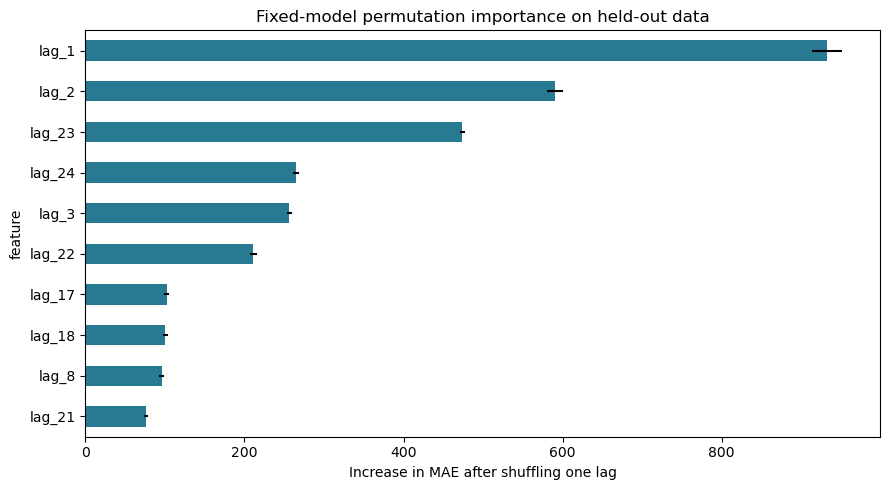

In [4]:
importance=permutation_importance(model,X,audit.target,n_repeats=5,random_state=42,
                                 scoring='neg_mean_absolute_error')
global_importance=pd.DataFrame({'feature':features,'MAE_increase':importance.importances_mean,
                                'repeat_std':importance.importances_std}).sort_values('MAE_increase',ascending=False)
display(global_importance.head(10))
global_importance.to_csv('feature-importance.csv',index=False)
selected=global_importance.head(10).sort_values('MAE_increase')
ax=selected.plot.barh(x='feature',y='MAE_increase',xerr='repeat_std',legend=False,
                      figsize=(9,5),color='#287a92',title='Fixed-model permutation importance on held-out data')
ax.set_xlabel('Increase in MAE after shuffling one lag')
plt.tight_layout()
plt.savefig('feature-importance.png',dpi=150)
plt.show()

## Exact local explanation of the selected linear SVR

The validation-selected SVR has a linear kernel. Decompose its prediction
into the intercept and scaled feature terms, then verify the sum against
the estimator. The reference for each term is the input scaler's zero,
corresponding to a training minimum. Correlated lags can have cancelling
contributions; these terms are an algebraic explanation, not causal effects.

In [5]:
pipeline=model.regressor_
scaler=pipeline.named_steps['minmaxscaler']
svr=pipeline.named_steps['svr']
assert svr.kernel=='linear'
point=X.iloc[[0]]
scaled=scaler.transform(point)[0]
target_scale=model.transformer_.scale_[0]
contributions=svr.coef_.ravel()*scaled/target_scale
intercept=(svr.intercept_[0]-model.transformer_.min_[0])/target_scale
reconstructed=intercept+contributions.sum()
np.testing.assert_allclose(reconstructed,model.predict(point)[0],rtol=1e-10)
local=pd.DataFrame({'feature':features,'input':point.iloc[0].to_numpy(),
                    'contribution_in_load_units':contributions})
display(local.assign(magnitude=local.contribution_in_load_units.abs()).nlargest(8,'magnitude').drop(columns='magnitude'))
print('Intercept:',intercept,'Sum of contributions:',contributions.sum(),'Prediction:',reconstructed)
local.to_csv('local-explanation.csv',index=False)
scenarios=[]
for multiplier in [0.9,1,1.1]:
    changed=point.copy()
    changed['lag_1']=np.clip(float(point.lag_1.iloc[0])*multiplier,train.lag_1.min(),train.lag_1.max())
    scenarios.append({'lag_1':float(changed.lag_1.iloc[0]),'prediction':float(model.predict(changed)[0])})
print('Sensitivity scenarios, with all other recorded lags held fixed:')
display(pd.DataFrame(scenarios))
pd.DataFrame(scenarios).to_csv('sensitivity-scenarios.csv',index=False)

,feature,input,contribution_in_load_units
0,lag_1,2723.0,804.648046
1,lag_2,2954.0,-777.427577
2,lag_3,3245.0,506.088833
22,lag_23,2781.0,470.559510
7,lag_8,3817.0,-337.695799
23,lag_24,2892.0,-335.221363
6,lag_7,3915.0,285.203498
3,lag_4,3535.0,-225.783629


Intercept: 2250.7827265022197 Sum of contributions: 305.38247126437597 Prediction: 2556.1651977665956
Sensitivity scenarios, with all other recorded lags held fixed:


,lag_1,prediction
0,2450.7,2109.921485
1,2723.0,2556.165198
2,2995.3,3002.408910


## Conclusions and limits

Overall error can hide differences by hour and day type. The cohort table
includes support counts and underprediction rates, while representation
checks establish which hours appear in the data. There are no demographic
labels, so these results cannot establish demographic fairness.

Permutation importance measures reliance on a feature in this sample and
can be diluted by correlated lags. The local decomposition is exact for
this fitted linear model and depends on its chosen reference. The
single-lag sensitivity examples may be inconsistent with a real load
trajectory. Neither they nor the error tree show that intervening on one
recorded feature would change electricity consumption. No causal study,
external dashboard execution, or operator trial is claimed.